# 02 — Comparison of the evaluation protocols

The thesis evaluates every model under two protocols (decision D06 in `docs/DECISIONS.md`):
- **Protocol A** — the official MERGE split `tvt_70_15_15`;
- **Protocol B** — the artist-grouped split `artist_70_15_15` produced by `src/splits.py`, in which every artist appears in only one set.

The difference between a model's scores under A and B is meant to measure how much the model relies on recognising artists. That interpretation is valid only if the two protocols do not differ in other ways that affect difficulty. This notebook checks whether the sets of the two protocols are comparable in **class balance, genre composition, emotion labels and audio features**, and records how they differ in **artist composition**, which is the intended difference.

Only label, metadata and feature distributions are compared; no model is trained and no modelling choice is made here, so describing the test sets does not leak information into the models.

Figures and tables are saved to `results/splits/` with the prefix `02_`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATASET = ROOT / "data" / "raw" / "MERGE_Audio_Balanced"
FEATURES = ROOT / "data" / "features" / "features_librosa.csv"
EDA = ROOT / "results" / "eda"
OUT = ROOT / "results" / "splits"
OUT.mkdir(parents=True, exist_ok=True)

QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
PARTS = ["train", "validate", "test"]
PROTOCOLS = {
    "A (official)": DATASET / "tvt_dataframes" / "tvt_70_15_15" / "tvt_70_15_15_{part}_audio_balanced.csv",
    "B (artist-grouped)": OUT / "artist_70_15_15" / "artist_70_15_15_{part}_audio_balanced.csv",
}
PCOLORS = {"A (official)": "#555555", "B (artist-grouped)": "#0072B2"}
summary = {}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()


meta = pd.read_csv(DATASET / "merge_audio_balanced_metadata.csv")
av = pd.read_csv(DATASET / "merge_audio_balanced_av_values.csv")
feats = pd.read_csv(FEATURES)
base = meta[["Song", "Quadrant", "Artist", "Title", "Genres"]].merge(av, on="Song")
base["MainGenre"] = base["Genres"].fillna("Unknown").str.split(",").str[0]
base["near_boundary"] = ((base["Arousal"] - 0.5).abs() < 0.05) | ((base["Valence"] - 0.5).abs() < 0.05)

rows = []
for protocol, pattern in PROTOCOLS.items():
    for part in PARTS:
        ids = pd.read_csv(str(pattern).format(part=part))["Song"]
        rows.append(pd.DataFrame({"Song": ids, "Protocol": protocol, "Split": part}))
assign = pd.concat(rows, ignore_index=True)
data = assign.merge(base, on="Song")
print(data.groupby("Protocol").size())

Protocol
A (official)          3232
B (artist-grouped)    3232
dtype: int64


## 1. Size and class balance

**Purpose:** confirm that both protocols use all 3,232 songs exactly once and have the same class balance and similar set sizes.

In [2]:
coverage = data.groupby("Protocol")["Song"].agg(["count", "nunique"])
display(coverage)

sizes = pd.crosstab([data["Protocol"], data["Split"]], data["Quadrant"]).reindex(columns=QUADRANTS)
sizes["total"] = sizes.sum(axis=1)
sizes = sizes.reindex(pd.MultiIndex.from_product([PROTOCOLS, PARTS]))
sizes.to_csv(OUT / "02_sizes_by_protocol.csv")
display(sizes)

test_sets = {p: set(data.loc[(data["Protocol"] == p) & (data["Split"] == "test"), "Song"]) for p in PROTOCOLS}
shared_test = len(test_sets["A (official)"] & test_sets["B (artist-grouped)"])
print(f"Songs present in both test sets: {shared_test}")
summary["songs_in_both_test_sets"] = shared_test

,count,nunique
Protocol,,
A (official),3232,3232
B (artist-grouped),3232,3232


Quadrant                      Q1   Q2   Q3   Q4  total
A (official)       train     566  566  566  566   2264
                   validate  121  121  121  121    484
                   test      121  121  121  121    484
B (artist-grouped) train     576  577  578  577   2308
                   validate  116  115  115  116    462
                   test      116  116  115  115    462

Songs present in both test sets: 80


**Findings.** Both protocols assign each of the 3,232 songs to exactly one set. Protocol A has exactly 121 songs per quadrant in the test set; protocol B has 115–116, a difference caused by moving whole artists. Only 80 songs are in both test sets, so the two protocols evaluate on largely different songs.

## 2. Artist composition — the intended difference

**Purpose:** document how the protocols differ in the property they are designed to differ in. Under protocol A many evaluation songs come from artists seen in training; under B none do. The section also checks whether B places the artists with many songs in a particular set, which would change the kind of music in that set.

,protocol,set,songs,distinct artists,songs with artist in train,share with artist in train
0,A (official),validate,484,389,307,0.634
1,A (official),test,484,370,320,0.661
2,B (artist-grouped),validate,462,232,0,0.000
3,B (artist-grouped),test,462,229,0,0.000


artist_size_group            1 song  2–5 songs  6–15 songs  > 15 songs
A (official)       train      0.342      0.414       0.172       0.071
                   validate   0.291      0.442       0.184       0.083
                   test       0.269      0.415       0.213       0.103
B (artist-grouped) train      0.323      0.422       0.180       0.075
                   validate   0.329      0.405       0.199       0.067
                   test       0.320      0.416       0.162       0.102

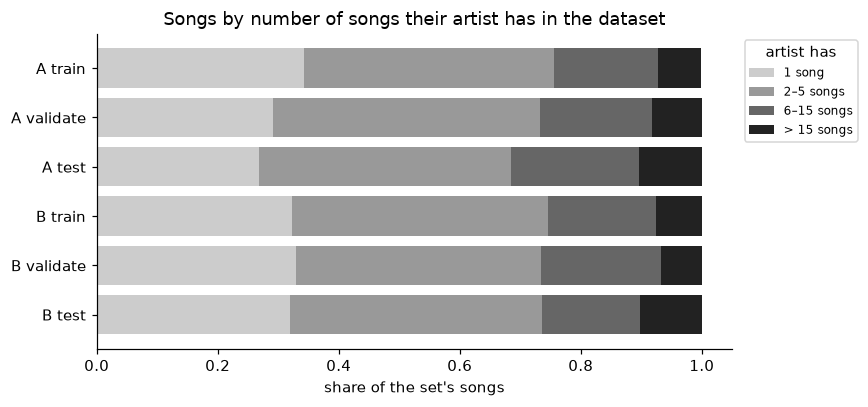

In [3]:
songs_per_artist = base["Artist"].value_counts()
data["artist_size"] = data["Artist"].map(songs_per_artist).fillna(1)
data["artist_size_group"] = pd.cut(data["artist_size"], [0, 1, 5, 15, 100], labels=["1 song", "2–5 songs", "6–15 songs", "> 15 songs"])

artist_rows = []
for protocol in PROTOCOLS:
    d = data[data["Protocol"] == protocol]
    train_artists = set(d.loc[d["Split"] == "train", "Artist"].dropna())
    for part in ["validate", "test"]:
        s = d[d["Split"] == part]
        artist_rows.append({
            "protocol": protocol,
            "set": part,
            "songs": len(s),
            "distinct artists": s["Artist"].nunique(),
            "songs with artist in train": int(s["Artist"].isin(train_artists).sum()),
            "share with artist in train": round(float(s["Artist"].isin(train_artists).mean()), 3),
        })
artist_table = pd.DataFrame(artist_rows)
artist_table.to_csv(OUT / "02_artist_overlap_by_protocol.csv", index=False)
display(artist_table)

size_table = pd.crosstab([data["Protocol"], data["Split"]], data["artist_size_group"], normalize="index").round(3)
size_table = size_table.reindex(pd.MultiIndex.from_product([PROTOCOLS, PARTS]))
size_table.to_csv(OUT / "02_artist_size_by_set.csv")
display(size_table)

fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [f"{p.split()[0]} {s}" for p in PROTOCOLS for s in PARTS]
left = np.zeros(len(labels))
palette = ["#CCCCCC", "#999999", "#666666", "#222222"]
for col, color in zip(size_table.columns, palette):
    ax.barh(labels, size_table[col].values, left=left, color=color, label=str(col))
    left += size_table[col].values
ax.invert_yaxis()
ax.set_xlabel("share of the set's songs")
ax.set_title("Songs by number of songs their artist has in the dataset")
ax.legend(title="artist has", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "02_artist_size_by_set")

summary["artist_overlap"] = artist_table.to_dict(orient="records")

**Findings.** The intended difference is confirmed: 66% of the test songs in A come from artists present in training, against 0% in B. B's test set contains fewer distinct artists (229 against 370), because artists move with all their songs. The share of songs from artists with many songs is similar in the two test sets (about 10% from artists with more than 15 songs in both).

## 3. Genre composition

**Purpose:** genre is strongly associated with quadrant (EDA §6). If the test set of B contained a different mix of genres than the test set of A, a score difference between the protocols could come from the genre mix rather than from the artists. The test compares the main-genre distribution of the two test sets with a chi-square test and reports the total variation distance (half the sum of absolute differences in shares; 0 means identical distributions, 1 completely different).

Genre mix, test A vs test B: chi2=24.7, dof=10, p=0.006, total variation distance=0.137


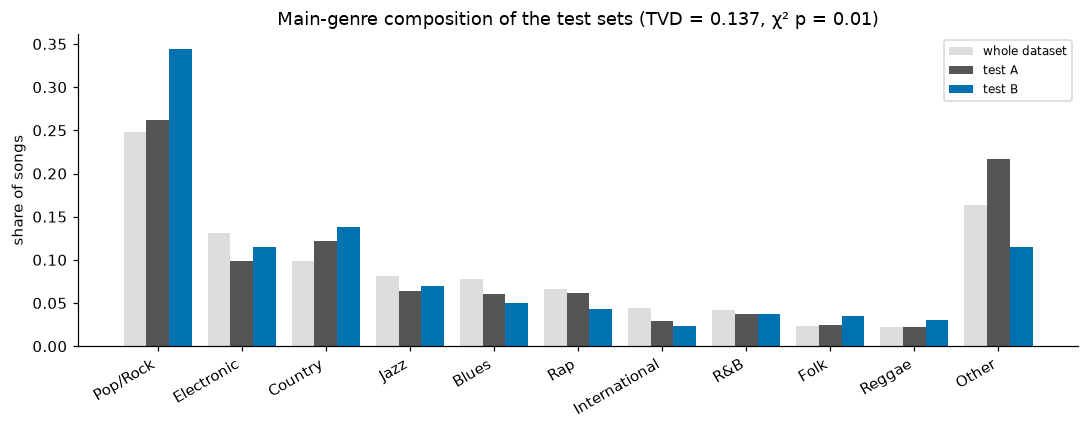

Cramér's V between genre and quadrant inside each test set: {'A test': 0.336, 'B test': 0.384}


In [4]:
top_genres = base["MainGenre"].value_counts().head(10).index
data["GenreGroup"] = np.where(data["MainGenre"].isin(top_genres), data["MainGenre"], "Other")
order = list(top_genres) + ["Other"]

shares = pd.crosstab([data["Protocol"], data["Split"]], data["GenreGroup"], normalize="index")[order]
shares = shares.reindex(pd.MultiIndex.from_product([PROTOCOLS, PARTS]))
shares.round(3).to_csv(OUT / "02_genre_share_by_set.csv")

test_a = data[(data["Protocol"] == "A (official)") & (data["Split"] == "test")]
test_b = data[(data["Protocol"] == "B (artist-grouped)") & (data["Split"] == "test")]
table = pd.DataFrame({"A test": test_a["GenreGroup"].value_counts(), "B test": test_b["GenreGroup"].value_counts()}).reindex(order).fillna(0)
chi2, p, dof, _ = stats.chi2_contingency(table.T.values)
tvd = 0.5 * (table["A test"] / table["A test"].sum() - table["B test"] / table["B test"].sum()).abs().sum()
print(f"Genre mix, test A vs test B: chi2={chi2:.1f}, dof={dof}, p={p:.3f}, total variation distance={tvd:.3f}")

dataset_share = base["MainGenre"].where(base["MainGenre"].isin(top_genres), "Other").value_counts(normalize=True).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(order))
w = 0.27
ax.bar(x - w, dataset_share.values, w, color="#DDDDDD", label="whole dataset")
ax.bar(x, shares.loc[("A (official)", "test")].values, w, color=PCOLORS["A (official)"], label="test A")
ax.bar(x + w, shares.loc[("B (artist-grouped)", "test")].values, w, color=PCOLORS["B (artist-grouped)"], label="test B")
ax.set_xticks(x, order, rotation=30, ha="right")
ax.set_ylabel("share of songs")
ax.set_title(f"Main-genre composition of the test sets (TVD = {tvd:.3f}, χ² p = {p:.2f})")
ax.legend(fontsize=8)
save(fig, "02_genre_share_test_sets")

genre_quadrant = {}
for name, s in [("A test", test_a), ("B test", test_b)]:
    t = pd.crosstab(s["GenreGroup"], s["Quadrant"]).reindex(index=order, columns=QUADRANTS).fillna(0)
    c2, _, _, _ = stats.chi2_contingency(t[(t.sum(axis=1) > 0)])
    genre_quadrant[name] = round(float(np.sqrt(c2 / (t.values.sum() * 3))), 3)
print("Cramér's V between genre and quadrant inside each test set:", genre_quadrant)

summary["genre_test_chi2_p"] = round(float(p), 4)
summary["genre_test_tvd"] = round(float(tvd), 4)
summary["genre_quadrant_cramers_v_in_test"] = genre_quadrant

**Findings.** The genre mix of the two test sets differs moderately but significantly (chi-square p ≈ 0.006, total variation distance ≈ 0.14). B's test set contains more Pop/Rock (about 34% against 26%) and fewer songs from the less frequent genres grouped as *Other* (about 12% against 22%). This is a side effect of grouping by artist: an artist's songs share a genre, so genres move in blocks. Inside each test set, genre is associated with quadrant to a similar degree (Cramér's V ≈ 0.34 in A and 0.38 in B).

**Consequence:** part of a score difference between A and B could come from the different genre mix, not only from unseen artists. This is recorded as decision D12.

## 4. Emotion labels

**Purpose:** a test set with more samples close to a quadrant boundary is harder regardless of the model. The arousal and valence distributions of the two test sets are compared with the two-sample Kolmogorov–Smirnov test (which measures the largest difference between two cumulative distributions), and the share of samples within 0.05 of a boundary is compared per quadrant.

,variable,mean A test,mean B test,KS statistic,KS p
0,Arousal,0.4738,0.4815,0.0345,0.9280
1,Valence,0.5200,0.5120,0.0504,0.5632


,A test,B test
Quadrant,,
Q1,0.116,0.103
Q2,0.545,0.526
Q3,0.207,0.200
Q4,0.091,0.052
all,0.240,0.221


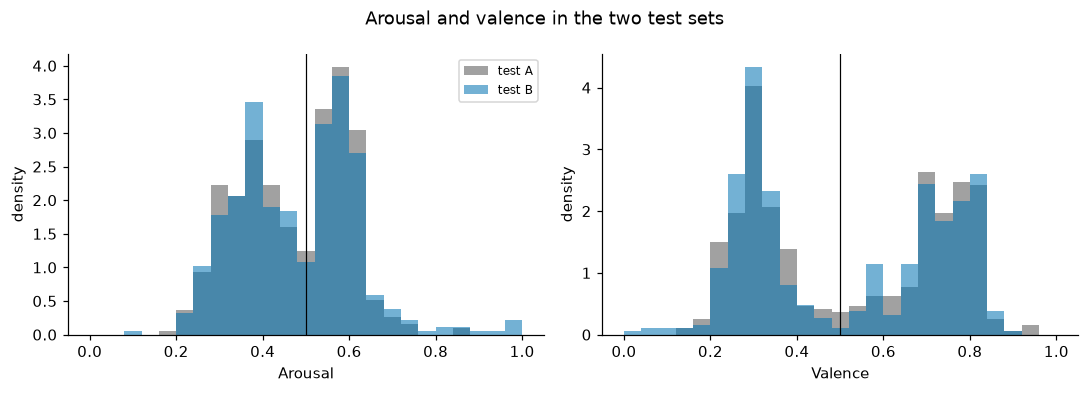

In [5]:
label_rows = []
for col in ["Arousal", "Valence"]:
    ks = stats.ks_2samp(test_a[col], test_b[col])
    label_rows.append({"variable": col, "mean A test": test_a[col].mean(), "mean B test": test_b[col].mean(), "KS statistic": ks.statistic, "KS p": ks.pvalue})
label_table = pd.DataFrame(label_rows).round(4)
label_table.to_csv(OUT / "02_label_distribution_test_sets.csv", index=False)
display(label_table)

near = pd.DataFrame({
    "A test": test_a.groupby("Quadrant")["near_boundary"].mean(),
    "B test": test_b.groupby("Quadrant")["near_boundary"].mean(),
}).reindex(QUADRANTS)
near.loc["all"] = [test_a["near_boundary"].mean(), test_b["near_boundary"].mean()]
near = near.round(3)
near.to_csv(OUT / "02_near_boundary_test_sets.csv")
display(near)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col in zip(axes, ["Arousal", "Valence"]):
    bins = np.linspace(0, 1, 26)
    ax.hist(test_a[col], bins=bins, alpha=0.55, color=PCOLORS["A (official)"], label="test A", density=True)
    ax.hist(test_b[col], bins=bins, alpha=0.55, color=PCOLORS["B (artist-grouped)"], label="test B", density=True)
    ax.axvline(0.5, color="black", lw=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("density")
axes[0].legend(fontsize=8)
fig.suptitle("Arousal and valence in the two test sets")
save(fig, "02_labels_test_sets")

summary["labels_ks"] = {r["variable"]: {"statistic": r["KS statistic"], "p": r["KS p"]} for r in label_rows}
summary["near_boundary_share_test"] = near.loc["all"].to_dict()

**Findings.** The emotion labels of the two test sets are statistically indistinguishable (Kolmogorov–Smirnov p ≈ 0.93 for arousal and 0.56 for valence). The share of samples near a quadrant boundary is similar (24% in A, 22% in B), so B's test set is not harder in terms of label ambiguity.

## 5. Audio features

**Purpose:** check that the test sets do not differ in the audio features the models rely on. For the ten features that separate the quadrants best on the official training set (EDA §8, `results/eda/08_feature_ranking_kruskal_train.csv`), the two test sets are compared with the standardised mean difference (SMD: difference of means divided by the pooled standard deviation; |SMD| < 0.1 is conventionally considered negligible and < 0.2 small) and the KS test.

,feature,SMD (B − A),KS statistic,KS p
0,spectral_contrast_03_mean,-0.0937,0.0670,0.2256
1,spectral_contrast_02_mean,-0.0447,0.0516,0.5335
2,spectral_contrast_04_mean,-0.0547,0.0835,0.0686
3,mfcc_01_mean,0.0628,0.0591,0.3617
4,spectral_contrast_05_mean,-0.0566,0.0750,0.1314
5,zcr_mean,0.0678,0.0615,0.3161
6,chroma_04_mean,0.0874,0.0660,0.2402
7,spectral_centroid_mean,0.0216,0.0520,0.5214
8,chroma_09_mean,-0.0453,0.0677,0.2159
9,spectral_contrast_05_std,-0.0730,0.0632,0.2863


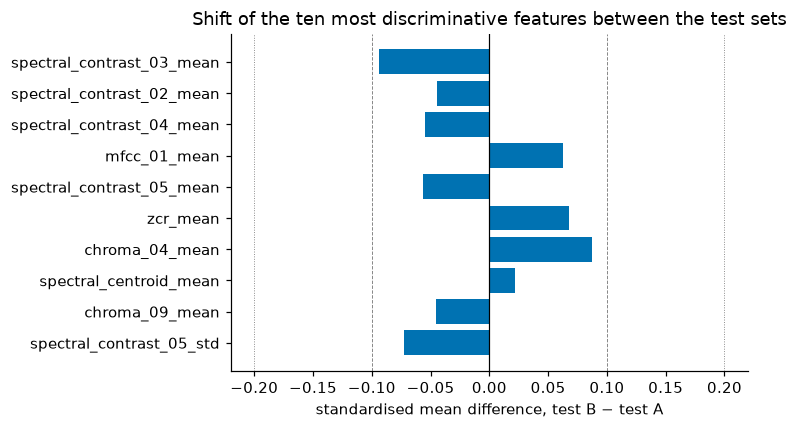

In [6]:
ranking = pd.read_csv(EDA / "08_feature_ranking_kruskal_train.csv")
top_features = ranking["feature"].head(10).tolist()
fa = feats.set_index("Song").loc[test_a["Song"], top_features]
fb = feats.set_index("Song").loc[test_b["Song"], top_features]

feat_rows = []
for col in top_features:
    pooled = np.sqrt((fa[col].var() + fb[col].var()) / 2)
    ks = stats.ks_2samp(fa[col], fb[col])
    feat_rows.append({"feature": col, "SMD (B − A)": (fb[col].mean() - fa[col].mean()) / pooled, "KS statistic": ks.statistic, "KS p": ks.pvalue})
feat_table = pd.DataFrame(feat_rows).round(4)
feat_table.to_csv(OUT / "02_feature_shift_test_sets.csv", index=False)
display(feat_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(feat_table["feature"], feat_table["SMD (B − A)"], color=PCOLORS["B (artist-grouped)"])
for v in [-0.2, -0.1, 0.1, 0.2]:
    ax.axvline(v, color="grey", lw=0.6, ls="--" if abs(v) == 0.1 else ":")
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("standardised mean difference, test B − test A")
ax.set_title("Shift of the ten most discriminative features between the test sets")
save(fig, "02_feature_shift_test_sets")

summary["feature_max_abs_smd"] = round(float(feat_table["SMD (B − A)"].abs().max()), 4)
summary["features_with_ks_p_below_0.05"] = feat_table.loc[feat_table["KS p"] < 0.05, "feature"].tolist()

**Findings.** None of the ten most discriminative features differs between the two test sets: every |SMD| is below 0.1 (negligible) and no KS test is significant at 0.05. In terms of the information the models use, the two test sets are comparable.

## 6. Summary

**Conclusion.** The two protocols are comparable in class balance, emotion labels and audio features, and differ as intended in artist overlap. They also differ moderately in genre mix, which is a side effect of grouping by artist. Decision D12 addresses this by repeating protocol B with several random seeds, so that the reported result does not depend on one particular genre mix.

All numbers are written to `results/splits/02_split_comparison_summary.json`, referenced by decision D12 in `docs/DECISIONS.md`.

In [7]:
(OUT / "02_split_comparison_summary.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
print(json.dumps(summary, indent=2, default=float))

{
  "songs_in_both_test_sets": 80,
  "artist_overlap": [
    {
      "protocol": "A (official)",
      "set": "validate",
      "songs": 484,
      "distinct artists": 389,
      "songs with artist in train": 307,
      "share with artist in train": 0.634
    },
    {
      "protocol": "A (official)",
      "set": "test",
      "songs": 484,
      "distinct artists": 370,
      "songs with artist in train": 320,
      "share with artist in train": 0.661
    },
    {
      "protocol": "B (artist-grouped)",
      "set": "validate",
      "songs": 462,
      "distinct artists": 232,
      "songs with artist in train": 0,
      "share with artist in train": 0.0
    },
    {
      "protocol": "B (artist-grouped)",
      "set": "test",
      "songs": 462,
      "distinct artists": 229,
      "songs with artist in train": 0,
      "share with artist in train": 0.0
    }
  ],
  "genre_test_chi2_p": 0.006,
  "genre_test_tvd": 0.1366,
  "genre_quadrant_cramers_v_in_test": {
    "A test": 0.336,
